# Amazon "Phone" Search Results — Data Cleaning & EDA
**Data Analysis Diploma · Final Project · Notebook 1 of 1**

**Pipeline:** `Raw CSV → Python (clean + feature engineering) → SQL Server (store, validate, model views) → Power BI (dashboard)`

| Item | Detail |
|---|---|
| Dataset | `phone_search_raw.csv` — 340 rows × 20 columns |
| What it is | Product listings returned by an Amazon.com (US) search for the keyword **"phone"** |
| Source | Scraped via a real-time Amazon product-search API (RapidAPI *Real-Time Amazon Data* schema — the column names match its `search` endpoint) |
| Snapshot date | **19 Sep 2024** (derived: delivery text says *"Tomorrow, Sep 20"*) |
| Currency | USD |

This notebook (1) profiles the raw data, (2) logs every quality problem, (3) fixes each one with an explained rule, (4) engineers analysis-ready features, and (5) exports the clean file that SQL Server and Power BI consume.

In [1]:
import pandas as pd, numpy as np, re, html
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

RAW  = '../01_Data/raw/phone_search_raw.csv'
OUT  = '../01_Data/clean/'
SNAPSHOT_DATE = pd.Timestamp('2024-09-19')

raw = pd.read_csv(RAW)
print(raw.shape)
raw.head(3)

(340, 20)


,asin,product_title,product_price,product_original_price,currency,product_star_rating,product_num_ratings,product_num_offers,product_minimum_offer_price,is_best_seller,is_amazon_choice,is_prime,product_availability,climate_pledge_friendly,sales_volume,delivery,has_variations,unit_price,unit_count,coupon_text
0,B0BQ118F2T,Moto G Play 2023 3-Day Battery Unlocked Made f...,$99.00,$169.99,USD,4.0,1319,16,$69.88,False,False,True,Only 1 left in stock - order soon.,False,4K+ bought in past month,"FREE delivery Tue, Sep 24 Only 1 left in stock...",False,NaN,NaN,NaN
1,B0CV2W1TKZ,"Samsung Galaxy A15 (SM-155M/DSN), 128GB 6GB RA...",$153.99,NaN,USD,4.2,186,4,$147.50,False,False,True,NaN,False,1K+ bought in past month,"FREE delivery Tue, Sep 24",False,NaN,NaN,NaN
2,B09SM24S8C,"Samsung Galaxy A03s Cell Phone, AT&amp;T GSM U...",$69.00,$99.99,USD,3.8,597,35,$64.99,False,False,True,NaN,False,2K+ bought in past month,"FREE delivery Tue, Sep 24",True,NaN,NaN,NaN


## 1. Profiling — what is wrong with the raw data?

In [2]:
profile = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'nulls': raw.isna().sum(),
    'null_%': (raw.isna().mean()*100).round(1),
    'unique': raw.nunique(),
    'example': raw.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None)
})
profile

,dtype,nulls,null_%,unique,example
asin,str,0,0.0,315,B0BQ118F2T
product_title,str,0,0.0,315,Moto G Play 2023 3-Day Battery Unlocked Made f...
product_price,str,4,1.2,241,$99.00
product_original_price,str,192,56.5,108,$169.99
currency,str,4,1.2,1,USD
product_star_rating,float64,3,0.9,22,4.0
product_num_ratings,int64,0,0.0,284,1319
product_num_offers,int64,0,0.0,38,16
product_minimum_offer_price,str,4,1.2,273,$69.88
is_best_seller,bool,0,0.0,2,False


In [3]:
print('Exact duplicate rows      :', raw.duplicated().sum())
print('Duplicate ASINs (any diff):', raw.asin.duplicated().sum())
print('Titles with HTML entities :', raw.product_title.str.contains('&amp;|&quot;|&#', regex=True).sum())
print('Prices stored as text     :', raw.product_price.dropna().str.startswith('$').all())
print('\nsales_volume values:'); print(raw.sales_volume.value_counts(dropna=False))

Exact duplicate rows      : 21
Duplicate ASINs (any diff): 25
Titles with HTML entities : 116
Prices stored as text     : True

sales_volume values:
sales_volume
100+ bought in past month                                                                                                                                                       49
200+ bought in past month                                                                                                                                                       44
500+ bought in past month                                                                                                                                                       41
50+ bought in past month                                                                                                                                                        39
1K+ bought in past month                                                                                                  

### Issues found (data-quality log)
| # | Issue | Column(s) | Rows | Fix |
|---|---|---|---|---|
| 1 | Exact duplicate rows (same product scraped twice across result pages) | all | 21 | Drop exact duplicates |
| 2 | Near-duplicates: same ASIN, slightly different price/stock | asin | 4 | Keep the **first** occurrence (highest search rank) |
| 3 | Prices stored as text with `$`, commas, trailing spaces | 3 price cols | all | Strip symbols → `float` |
| 4 | Listings with no price / currency (unavailable offers) | price, currency | 4 | Remove from fact table, keep in `rejected_rows.csv` |
| 5 | `product_original_price` null when no discount | original price | ~57% | Null = "no list price" → set equal to price, discount = 0 |
| 6 | HTML entities in titles (`&amp;`, `&quot;`) | title | 116 | `html.unescape()` |
| 7 | `sales_volume` is free text ("1K+ bought in past month") | sales_volume | all | Parse to integer lower bound (1K+ → 1000) |
| 8 | Wrong values scraped into `sales_volume` ("More Buying Choices", "List:") | sales_volume | 21 | Treat as missing badge |
| 9 | Missing sales badge (Amazon hides it under 50 units) | sales_volume | 20 | Band = "<50 / not shown", units = 0 |
| 10 | Stock text merged into `delivery` column ("…Sep 24 Only 1 left in stock") | delivery | 75 | Regex-split into stock & delivery |
| 11 | Delivery is free text with relative dates ("Tomorrow, Sep 20") | delivery | all | Extract fee type + first date → `days_to_delivery` |
| 12 | `product_availability` text only ("Only 3 left…") | availability | 75 | Extract `stock_left` integer; null = in stock |
| 13 | `unit_price`, `unit_count` ~99% empty; `currency` constant | 3 cols | — | Drop (no analytical value) |
| 14 | Coupon is free text ("Save 10%" / "Save $4.00") | coupon_text | 22 | Parse to type + value + $ saving |
| 15 | No brand / category / condition columns — mixed results (smartphones, landlines, cases, toys) | title | all | Rule-based extraction from title |
| 16 | Brand spelling inconsistent (SAMSUNG/Samsung, Moto/Motorola, carrier prefixes "TracFone \| …") | title | 68 | Normalise with a mapping table |
| 17 | 3 products with 0 reviews → rating null | star_rating | 3 | Keep null (not 0) + flag `is_rated` |

## 2. Cleaning

### 2.1 Duplicates (issues 1–2)

In [4]:
df = raw.copy()
df['search_rank'] = np.arange(1, len(df)+1)          # position in the search results
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in raw.columns])  # exact duplicates
n1 = len(df)
df = df.drop_duplicates(subset='asin', keep='first')      # near-duplicates (same product)
n2 = len(df)
print(f'{n0} → {n1} after exact dups (-{n0-n1}) → {n2} after ASIN dups (-{n1-n2})')

340 → 319 after exact dups (-21) → 315 after ASIN dups (-4)


### 2.2 Prices, discounts and missing prices (issues 3–5)

In [5]:
def money(s):
    return pd.to_numeric(s.astype('string').str.replace(r'[\$,\s]', '', regex=True), errors='coerce')

df['price']            = money(df.product_price)
df['list_price']       = money(df.product_original_price)
df['min_offer_price']  = money(df.product_minimum_offer_price)

rejected = df[df.price.isna()].assign(reject_reason='No price / currency (offer unavailable)')
df = df[df.price.notna()].copy()

df['has_discount']  = df.list_price.notna()
df['list_price']    = df.list_price.fillna(df.price)
df['discount_amt']  = (df.list_price - df.price).round(2)
df['discount_pct']  = (df.discount_amt / df.list_price).round(4)

# sanity rules
assert (df.list_price >= df.price).all()
assert (df.min_offer_price.fillna(0) <= df.price).all()
print('Rows kept:', len(df), '| rejected:', len(rejected))
df[['price','list_price','discount_pct','min_offer_price']].describe().round(2)

Rows kept: 311 | rejected: 4


,price,list_price,discount_pct,min_offer_price
count,311.0,311.0,311.0,311.0
mean,171.83,198.05,0.09,146.14
std,202.16,239.82,0.15,190.49
min,7.99,7.99,0.0,7.99
25%,59.99,65.47,0.0,43.94
50%,113.87,124.0,0.0,82.17
75%,199.99,204.97,0.14,164.97
max,1614.99,2019.99,0.75,1583.65


### 2.3 Text clean-up: titles (issue 6)

In [6]:
df['title'] = (df.product_title.map(html.unescape)
                 .str.replace('\u200b', '', regex=False)
                 .str.replace(r'\s+', ' ', regex=True).str.strip())
df['title'].str.contains('&amp;').sum()

np.int64(0)

### 2.4 Sales volume → units (issues 7–9)
Amazon only shows *"X+ bought in past month"* when a product sells **≥ 50 units/month**. So the badge is a **lower bound**, and a missing badge means "under 50". Two scraped values (*More Buying Choices*, *List:*) are labels from neighbouring page elements — they are treated as missing.

In [7]:
def parse_units(s):
    if pd.isna(s): return np.nan
    m = re.match(r'(\d+(?:\.\d+)?)(K?)\+ bought', s)
    if not m: return np.nan                     # mis-scraped label
    return int(float(m.group(1)) * (1000 if m.group(2) else 1))

df['sales_badge_raw']   = df.sales_volume
df['monthly_units_min'] = df.sales_volume.map(parse_units)
df['sales_badge_shown'] = df.monthly_units_min.notna()
df['monthly_units_min'] = df.monthly_units_min.fillna(0).astype(int)

def band(u):
    if u == 0: return '0. <50 / not shown'
    if u < 200: return '1. 50–199'
    if u < 500: return '2. 200–499'
    if u < 1000: return '3. 500–999'
    return '4. 1K+'
df['sales_band'] = df.monthly_units_min.map(band)
df['est_monthly_revenue'] = (df.price * df.monthly_units_min).round(2)   # lower-bound revenue
df.sales_band.value_counts().sort_index()

sales_band
0. <50 / not shown    43
1. 50–199             84
2. 200–499            97
3. 500–999            41
4. 1K+                46
Name: count, dtype: int64

### 2.5 Stock & delivery (issues 10–12)

In [8]:
stock_pat = r'Only (\d+) left in stock'
stock_from_avail    = df.product_availability.str.extract(stock_pat)[0]
stock_from_delivery = df.delivery.str.extract(stock_pat)[0]
df['stock_left'] = pd.to_numeric(stock_from_avail.fillna(stock_from_delivery))
df['is_low_stock'] = df.stock_left.le(10).fillna(False)
df['out_of_stock'] = df.delivery.str.contains('out of stock', case=False, na=False)

d = df.delivery.str.replace(r'Only \d+ left in stock.*', '', regex=True).str.strip()
df['delivery_clean'] = d
df['free_delivery']  = d.str.startswith('FREE', na=False)
df['delivery_fee']   = pd.to_numeric(d.str.extract(r'^\$(\d+\.\d+) delivery')[0]).fillna(0)

def first_date(s):
    if pd.isna(s): return pd.NaT
    m = re.search(r'(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec) (\d{1,2})', s)
    return pd.Timestamp(f'2024-{m.group(1)}-{m.group(2)}') if m else pd.NaT
df['delivery_date'] = d.map(first_date)
df['days_to_delivery'] = (df.delivery_date - SNAPSHOT_DATE).dt.days
df['fast_delivery_option'] = d.str.contains('fastest delivery', na=False)
df[['delivery_clean','free_delivery','delivery_fee','delivery_date','days_to_delivery','stock_left']].head(8)

,delivery_clean,free_delivery,delivery_fee,delivery_date,days_to_delivery,stock_left
0,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,1.0
1,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,NaN
2,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,NaN
3,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,NaN
4,"FREE delivery Mon, Sep 30",True,0.0,2024-09-30,11.0,NaN
5,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,NaN
6,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,NaN
7,"FREE delivery Tue, Sep 24",True,0.0,2024-09-24,5.0,NaN


### 2.6 Coupons (issue 14)

In [9]:
c = df.coupon_text
df['has_coupon']   = c.notna()
df['coupon_type']  = np.select([c.str.contains('%', na=False), c.str.contains(r'\$', na=False)], ['Percent','Fixed $'], 'No coupon')
df['coupon_value'] = pd.to_numeric(c.str.extract(r'(\d+(?:\.\d+)?)')[0]).fillna(0)
df['coupon_saving_usd'] = np.where(df.coupon_type=='Percent', df.price*df.coupon_value/100, df.coupon_value).round(2)
df['net_price_after_coupon'] = (df.price - df.coupon_saving_usd).round(2)
df.loc[df.has_coupon, ['coupon_text','coupon_type','coupon_value','coupon_saving_usd']]

,coupon_text,coupon_type,coupon_value,coupon_saving_usd
65,Save 10% with coupon,Percent,10.0,1.00
100,Save $4.00 with coupon,Fixed $,4.0,4.00
146,Save $14.00 with coupon,Fixed $,14.0,14.00
157,Save 5% with coupon,Percent,5.0,1.80
160,Save $17.00 with coupon,Fixed $,17.0,17.00
195,Save 15% with coupon,Percent,15.0,3.30
198,Save $10.00 with coupon,Fixed $,10.0,10.00
218,Save $10.00 with coupon,Fixed $,10.0,10.00
240,Save 5% with coupon,Percent,5.0,1.50
242,Save 5% with coupon,Percent,5.0,1.50


### 2.7 Feature extraction from the title (issues 15–16)
The search returned **mixed product types**. Without a category column, any "average phone price" would mix a \$8 phone case with a \$1,600 foldable. Rules are applied in priority order and were checked manually against all 311 titles.

In [10]:
CARRIER_PREFIX = r'^(\[New\]\s*|TracFone\s*\|?\s*|Total by Verizon\s*\|?\s*|Simple Mobile\s*\|?\s*|Straight Talk\s*|Prepaid\s+)'
BRANDS = {   # regex anchored at start of title  →  canonical brand
 r'samsung': 'Samsung', r'moto(rola)?\b': 'Motorola', r'apple|iphone': 'Apple', r'google': 'Google',
 r'oneplus': 'OnePlus', r'nokia': 'Nokia', r'panasonic': 'Panasonic', r'vtech': 'VTech', r'at&t': 'AT&T',
 r'tcl': 'TCL', r'alcatel': 'Alcatel', r'blu\b': 'BLU', r'doogee': 'DOOGEE', r'xiaomi': 'Xiaomi',
 r'nothing|cmf': 'Nothing', r'kyocera': 'Kyocera', r'cat\b': 'CAT', r'umidigi': 'UMIDIGI', r'nuu': 'NUU',
 r'simbros': 'SIMBROS', r'bold\b': 'Bold', r'blackview': 'Blackview', r'cubot': 'CUBOT', r'oukitel': 'OUKITEL',
 r'lively': 'Lively', r'gabb': 'Gabb', r'hamilton': 'Hamilton', r'hellobaby': 'HelloBaby', r'zte': 'ZTE',
 r'yealink': 'Yealink', r'xblue': 'XBLUE', r'smpl': 'SMPL', r'sangyn': 'Sangyn', r'scosche': 'Scosche',
 r'spidercase': 'SPIDERCASE', r'team luxury': 'TEAM LUXURY', r'tocol': 'TOCOL', r'toneof': 'TONEOF',
 r'sensyne': 'Sensyne', r'agm\b': 'AGM',
}
def get_brand(t):
    s = re.sub(CARRIER_PREFIX, '', t, flags=re.I).lstrip('|- ').strip()
    for pat, b in BRANDS.items():
        if re.match(pat, s, flags=re.I): return b
    return 'Generic / Unbranded'

def get_seller_channel(t):
    m = re.match(r'^(TracFone|Total by Verizon|Simple Mobile|Straight Talk)', t, flags=re.I)
    names = {'tracfone':'TracFone','total by verizon':'Total by Verizon','simple mobile':'Simple Mobile','straight talk':'Straight Talk'}
    return names[m.group(1).lower()] if m else 'Open market'

ACCESSORY = r'\b(case|holder|mount|tripod|gimbal|charger|power bank|ring light|sim card|charging shelf|bluetooth speaker)\b'
LANDLINE  = r'cordless|corded|landline|telephone|\bdect\b|answering|handset|ip phone|office phone|add-on phone|wall phone|speakerphone|image phone'
BASIC     = r'\bflip\b|smartflip|feature phone|basic cell phone|jitterbug|nokia 110'
def get_category(t):
    tl = t.lower()
    if re.search(r'\btoys?\b', tl): return 'Kids Toy Phone'
    if re.search(LANDLINE, tl) and not re.search(r'android|smartphone', tl): return 'Landline / Cordless'
    if re.search(ACCESSORY, tl) and not re.search(r'galaxy|pixel|moto|nokia|redmi', tl[:40]): return 'Accessory'
    if re.search(BASIC, tl) and not re.search(r'galaxy|smartphone|\d+g/\d+gb', tl): return 'Basic / Flip Phone'
    return 'Smartphone'

df['brand']          = df.title.map(get_brand)
df['seller_channel'] = df.title.map(get_seller_channel)
df['category']       = df.title.map(get_category)
df.category.value_counts()

category
Smartphone             206
Landline / Cordless     76
Accessory               16
Basic / Flip Phone      11
Kids Toy Phone           2
Name: count, dtype: int64

In [11]:
# manual review sample per category
for cat, g in df.groupby('category'):
    print(f'--- {cat} ({len(g)})'); print('\n'.join(g.title.str[:85].head(4)))

--- Accessory (16)
SPIDERCASE Magnetic for iPhone 16 Plus Case,with 2 Pcs [Tempered Glass Screen Protect
Magnetic for iPhone 16 Case,[Compatible with MagSafe][Military Grade Drop Protection]
TEAM LUXURY for iPhone 15 Case, [Military Grade Protection] Scratch-Resistant Back, S
AT&T Essentials Edge Pro Case, Cell Phone Accessories, with Drop Protection for Apple
--- Basic / Flip Phone (11)
Alcatel SMARTFLIP 4052R | 4G LTE | 4GB Flip-Phone | Bluetooth, WiFi, Big Buttons | Ca
Cat S22 Flip (16GB) 2.8" Touchscreen, Android 11, IP68 Water Resistant, 4G LTE GSM (T
Nokia 2780 Flip | Unlocked | KaiOS | Verizon, AT&T, T-Mobile | Blue
Kyocera DuraXV Extreme E4810 Verizon Rugged LTE Flip Basic Cell Phone Camera GPS Blac
--- Kids Toy Phone (2)
Kids Smart Phone for Girls, Christmas Birthday Gifts for Girls Age 3-10 Kids Toys Cel
Kids Smart Phone Toys Cell Phone for Boys Girls Toddlers Baby Childrens 3-8 Years Old
--- Landline / Cordless (76)
Panasonic Cordless Phone with Answering Machine, Advanced C

In [12]:
mobile = df.category.isin(['Smartphone','Basic / Flip Phone'])
tl = df.title.str.lower()
df['condition'] = np.where(tl.str.contains('renewed'), 'Renewed', 'New')
df['lock_status'] = np.select(
    [~mobile, tl.str.contains(r'\bunlocked\b'), tl.str.contains(r'\blocked\b|verizon|t-mobile|tmobile|prepaid')],
    ['Not applicable', 'Unlocked', 'Carrier-locked'], 'Not stated')
df['is_5g'] = mobile & tl.str.contains(r'\b5g\b')

def storage_gb(t):
    t = t.replace('ROM','').replace('Storage','')
    pair = re.findall(r'(\d+)\s?(?:GB)?\s?[/+]\s?(\d+)\s?(?:GB|\|)', t, flags=re.I)
    vals = [int(x) for p in pair for x in p] + [int(x) for x in re.findall(r'(\d+)\s?GB', t, flags=re.I)]
    vals += [int(x)*1024 for x in re.findall(r'(\d)\s?TB', t)] if not vals else []
    vals = [v for v in vals if v in (4,8,16,32,64,128,256,512,1024)]
    return max(vals) if vals else np.nan
df['storage_gb'] = np.where(df.category=='Smartphone', df.title.map(storage_gb), np.nan)

df['price_band'] = pd.cut(df.price, [0,50,100,200,400,800,10_000],
                          labels=['<$50','$50–99','$100–199','$200–399','$400–799','$800+'], right=False).astype(str)
df['star_rating'] = df.product_star_rating
df['is_rated']    = df.product_num_ratings > 0
df['rating_band'] = pd.cut(df.star_rating, [0,3.5,4.0,4.5,5.01], labels=['<3.5','3.5–3.9','4.0–4.4','4.5–5.0'], right=False).astype(object).fillna('Not rated')
df[['brand','category','condition','lock_status','is_5g','storage_gb','price_band','rating_band']].sample(8, random_state=1)

,brand,category,condition,lock_status,is_5g,storage_gb,price_band,rating_band
105,AT&T,Landline / Cordless,New,Not applicable,False,NaN,<$50,4.0–4.4
222,Panasonic,Landline / Cordless,New,Not applicable,False,NaN,<$50,4.0–4.4
337,Generic / Unbranded,Accessory,New,Not applicable,False,NaN,$200–399,4.0–4.4
210,Panasonic,Landline / Cordless,New,Not applicable,False,NaN,<$50,4.0–4.4
102,OnePlus,Smartphone,New,Unlocked,False,512.0,$400–799,4.5–5.0
171,AT&T,Landline / Cordless,New,Not applicable,False,NaN,$50–99,4.0–4.4
339,Generic / Unbranded,Accessory,New,Not applicable,False,NaN,<$50,4.0–4.4
250,Generic / Unbranded,Landline / Cordless,New,Not applicable,False,NaN,<$50,<3.5


### 2.8 Final column set & export (issue 13: drop empty / constant columns)

In [13]:
final = df.rename(columns={'product_num_ratings':'num_ratings','product_num_offers':'num_offers'})[[
 'asin','search_rank','title','brand','category','condition','lock_status','seller_channel','is_5g','storage_gb',
 'price','list_price','discount_amt','discount_pct','has_discount','min_offer_price','price_band',
 'star_rating','rating_band','num_ratings','is_rated','num_offers',
 'is_best_seller','is_amazon_choice','is_prime','climate_pledge_friendly','has_variations',
 'monthly_units_min','sales_badge_shown','sales_band','est_monthly_revenue',
 'stock_left','is_low_stock','out_of_stock','free_delivery','delivery_fee','delivery_date','days_to_delivery','fast_delivery_option',
 'has_coupon','coupon_type','coupon_value','coupon_saving_usd','net_price_after_coupon']]
final['snapshot_date'] = SNAPSHOT_DATE.date()
final.to_csv(OUT+'phones_clean.csv', index=False, encoding='utf-8')
rejected[raw.columns.tolist()+['reject_reason']].to_csv(OUT+'rejected_rows.csv', index=False)
print(final.shape); final.isna().sum()[lambda s: s>0]

(311, 45)


storage_gb          115
star_rating           3
stock_left          239
delivery_date        15
days_to_delivery     15
dtype: int64

## 3. Exploratory analysis (feeds the dashboard story)

In [14]:
phones = final[final.category=='Smartphone']
kpi = {
 'Listings (clean)': len(final), 'Brands': final.brand.nunique(),
 'Median price $': final.price.median(), 'Avg rating': round(final.star_rating.mean(),2),
 'Est. monthly units (min)': final.monthly_units_min.sum(),
 'Est. monthly revenue $ (min)': round(final.est_monthly_revenue.sum()),
 '% discounted': round(final.has_discount.mean()*100,1),
 '% renewed (smartphones)': round((phones.condition=='Renewed').mean()*100,1),
}
pd.Series(kpi)

Listings (clean)                     311.00
Brands                                41.00
Median price $                       113.87
Avg rating                             4.09
Est. monthly units (min)          130550.00
Est. monthly revenue $ (min)    20680784.00
% discounted                          44.10
% renewed (smartphones)               34.50
dtype: float64

In [15]:
by_cat = final.groupby('category').agg(listings=('asin','count'), median_price=('price','median'),
          avg_rating=('star_rating','mean'), units=('monthly_units_min','sum'), revenue=('est_monthly_revenue','sum')).round(2)
by_cat['revenue_share_%'] = (by_cat.revenue/by_cat.revenue.sum()*100).round(1)
by_cat.sort_values('revenue', ascending=False)

,listings,median_price,avg_rating,units,revenue,revenue_share_%
category,,,,,,
Smartphone,206,154.64,4.04,84350,18048832.0,87.3
Landline / Cordless,76,59.02,4.16,31950,2012952.5,9.7
Basic / Flip Phone,11,64.89,3.81,4700,295214.0,1.4
Accessory,16,28.74,4.48,5550,195825.0,0.9
Kids Toy Phone,2,35.99,4.30,4000,127960.0,0.6


In [16]:
by_brand = final.groupby('brand').agg(listings=('asin','count'), median_price=('price','median'),
            avg_rating=('star_rating','mean'), units=('monthly_units_min','sum'), revenue=('est_monthly_revenue','sum')).round(1)
by_brand['revenue_share_%'] = (by_brand.revenue/by_brand.revenue.sum()*100).round(1)
by_brand.sort_values('revenue', ascending=False).head(10)

,listings,median_price,avg_rating,units,revenue,revenue_share_%
brand,,,,,,
Samsung,85,183.0,4.1,44700,9718181.0,47.0
Apple,16,220.5,4.2,13050,3297890.0,15.9
Motorola,38,101.1,4.1,12950,1616835.0,7.8
Google,13,172.5,4.2,4300,1588102.5,7.7
OnePlus,8,227.5,4.2,2900,1165748.0,5.6
Panasonic,18,100.0,4.3,11100,907825.0,4.4
AT&T,19,51.6,4.2,9850,552708.5,2.7
VTech,18,65.0,4.2,7000,399319.0,1.9
Generic / Unbranded,32,39.5,4.0,10250,370919.5,1.8


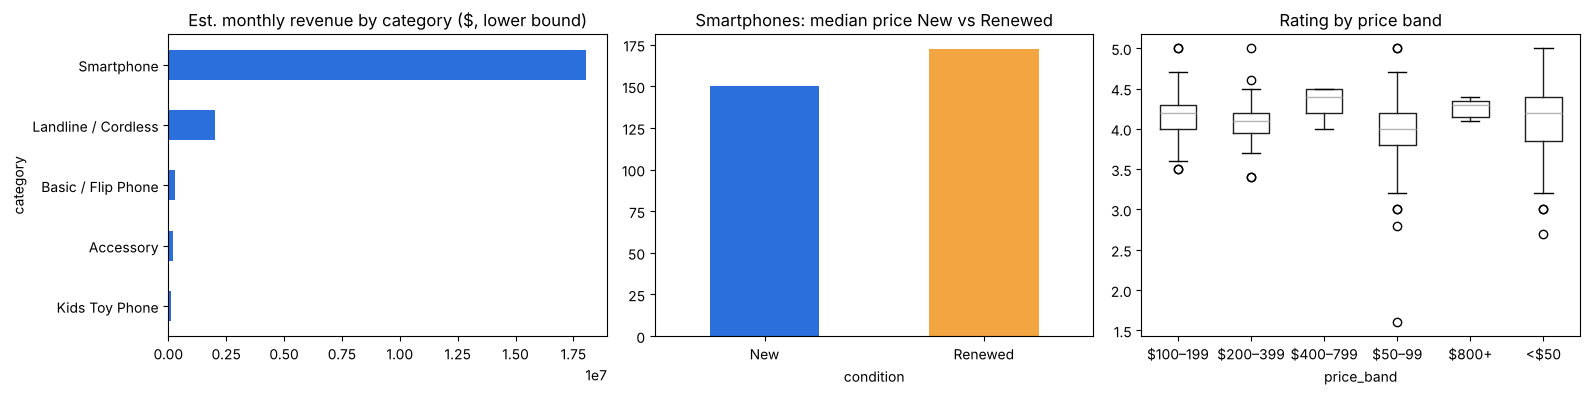

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16,4.2))
final.groupby('category').est_monthly_revenue.sum().sort_values().plot.barh(ax=ax[0], color='#2a6fdb'); ax[0].set_title('Est. monthly revenue by category ($, lower bound)')
phones.groupby('condition').price.median().plot.bar(ax=ax[1], color=['#2a6fdb','#f2a541'], rot=0); ax[1].set_title('Smartphones: median price New vs Renewed')
final.boxplot(column='star_rating', by='price_band', ax=ax[2], grid=False); ax[2].set_title('Rating by price band'); fig.suptitle('')
plt.tight_layout(); plt.savefig('charts/eda_overview.png', dpi=150); plt.show()

In [18]:
# Does a discount / badge / Prime correlate with sales? (association, not causation)
for col in ['has_discount','is_prime','is_amazon_choice','has_coupon','condition']:
    print(final.groupby(col).agg(listings=('asin','count'), avg_units=('monthly_units_min','mean'), median_price=('price','median')).round(1), '\n')

              listings  avg_units  median_price
has_discount                                   
False              174      346.8         114.4
True               137      512.4         111.1 

          listings  avg_units  median_price
is_prime                                   
False           84      423.2         181.5
True           227      418.5          98.2 

                  listings  avg_units  median_price
is_amazon_choice                                   
False                  310      408.2         114.1
True                     1     4000.0          50.0 

            listings  avg_units  median_price
has_coupon                                   
False            289      416.8         120.0
True              22      459.1          48.0 

           listings  avg_units  median_price
condition                                   
New             238      388.4         100.0
Renewed          73      521.9         170.0 



In [19]:
print('Correlation (Spearman) with monthly units:')
final[['price','discount_pct','star_rating','num_ratings','num_offers','monthly_units_min']].corr(method='spearman')['monthly_units_min'].round(2)

Correlation (Spearman) with monthly units:


price               -0.00
discount_pct         0.15
star_rating          0.05
num_ratings          0.38
num_offers           0.32
monthly_units_min    1.00
Name: monthly_units_min, dtype: float64

## 4. Hand-off
* `01_Data/clean/phones_clean.csv` → loaded into SQL Server by `03_SQL/02_load_data.sql`
* SQL views (`03_SQL/04_analysis_views.sql`) → imported into Power BI (`04_PowerBI/`)
* Notebook findings → presentation (`05_Presentation/`)